# Why predict survival from expression

The overview notebook ended on a bottleneck: 55% of a Primary tumor's clones
are never seen in its Secondary tumors, and the ones that make it tend to be
the bigger ones. This notebook asks whether that loss is random with respect
to what the cells look like:

**Do a clone's cells in the Primary tumor carry information about whether
it will survive, beyond how many of them there are?**

Two parts build the case:

1. **Fate is not just size.** Bigger clones survive more often, but a clone
   that does better than its size predicts in one family also does better in
   the other families. Survival is a property of the clone.
2. **Survivors already look different.** Comparing clones that survive with
   clones that are lost, at matched size, their Primary-tumor cells differ in
   state mix and in gene expression by more than chance.

If both hold, selection between Primary and Secondary is acting on clones,
and which Primary cells have descendants is a fact the barcodes record and
expression only partly reflects. The `coupling_ablation` notebook takes that
to the flow-matching setting, where the pairing of Primary and Secondary
cells is what a model trains on: it compares the pairing the barcodes give
with the one standard OT would infer from expression alone.

Naming follows the overview notebook: families A/B/C, tumors A1 → A2a/A2b →
A3a/A3b, generations Primary / Secondary / Tertiary. Only the metadata CSV
and the count matrix (`derived/etracer_counts.h5ad`) are read.

Terms used below are defined in `GLOSSARY.md`; code comments point to it as `GLOSSARY.md: term`.


In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd().parent / "src"))
import etracer as et

P = et.Paths(Path.cwd().parent)

STAGES = ["Primary", "Secondary", "Tertiary"]
FAMILIES = ["A", "B", "C"]
STATE_NAMES = ["Hypoxic", "Proliferative", "EMT", "Metabolic", "Interferon response"]
SURVIVED_COLOR, LOST_COLOR = "#2a78d6", "#eb6834"
MUTED = "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
})
# One generator for every shuffle and bootstrap below, so the notebook reruns identically.
rng = np.random.default_rng(0)

In [3]:
# Deposit names -> our names. The same mapping as the overview notebook, repeated so this
# notebook runs on its own. `cell_id` (not `cell`) is the key that matches the h5ad rows.
# GLOSSARY.md: family, generation / stage, tumor name, tumor state
FAMILY_OF = {"a3026": "A", "a3028": "B", "a3030": "C"}
STAGE_OF = {"BL": "Primary", "EE": "Secondary", "LE": "Tertiary"}
STATE_OF = dict(zip(et.STATES, STATE_NAMES))

def tumor_name(sample):
    parts = sample.split("_")
    gen, fam = parts[0][1], FAMILY_OF[parts[1]]
    return f"{fam}{gen}" + ("" if gen == "1" else "ab"[int(parts[2]) - 1])

raw = et.load_metadata(P)
meta = pd.DataFrame({
    "cell_id": raw["cell_id"],
    "tumor": raw["sample"].map(tumor_name),
    "family": raw["family"].map(FAMILY_OF),
    "stage": raw["stage"].map(STAGE_OF),
    "clone": raw["clone"].map(lambda c: f"clone {c[1:]}", na_action="ignore"),
    "state": pd.Categorical(raw["state"].map(STATE_OF), STATE_NAMES),
    "n_umi": raw["n_umi"],
})
called = meta[meta.clone.notna()]
print(f"{len(called):,} clone-called cells")


46,000 clone-called cells


## The unit: a clone in one Primary tumor

Each row below is one clone in one family's Primary tumor (clone 12 in A1,
clone 12 in B1, ...). It **survived** if any of its cells are seen in either
of that family's two Secondary tumors. Only the Primary → Secondary step is
used: it is where most clones are lost (the overview's survival bars), and it
has three to four times as many clones as Secondary → Tertiary, where
most size bins hold fewer than 50 clones.


In [4]:
primary = called[called.stage == "Primary"].groupby(["family", "clone"]).size().rename("n_parent")
secondary = called[called.stage == "Secondary"].groupby(["family", "clone"]).size().rename("n_child")

# `n_child` pools both Secondary tumors of the family; `survived` is any descendant seen in
# either. log size is the covariate every later adjustment uses.
# GLOSSARY.md: unit, survival (of a clone)
units = primary.to_frame().join(secondary, how="left").fillna({"n_child": 0}).reset_index()
units["survived"] = units.n_child > 0
units["log_n"] = np.log(units.n_parent)
print(f"{len(units)} clone-in-family units, {units.survived.mean():.0%} survived")
units.head()

462 clone-in-family units, 45% survived


,family,clone,n_parent,n_child,survived,log_n
0,A,clone 1,11,830.0,True,2.397895
1,A,clone 10,24,1.0,True,3.178054
2,A,clone 101,34,20.0,True,3.526361
3,A,clone 102,35,0.0,False,3.555348
4,A,clone 103,42,0.0,False,3.737670


## 1. Fate is not just size

The overview showed survival rising with clone size, partly because small
survivors can be missed (only about half of cells get a clone call). So
first: how much does size alone explain? Then: once size is accounted for,
does a clone's residual luck repeat across the three families, which are
independent mice seeded from the same barcoded pool?


In [5]:
# Survival ~ log(size) + family, by logistic regression: Newton's method on the logistic
# log-likelihood (IRLS), numpy only. The 1e-6 ridge keeps H invertible.
# GLOSSARY.md: logistic regression / IRLS, AUC
def fit_logistic(X, y, iters=50):
    w = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ w))
        H = X.T @ (X * (p * (1 - p))[:, None]) + 1e-6 * np.eye(X.shape[1])
        w += np.linalg.solve(H, X.T @ (y - p))
    return w

# Mann-Whitney form of the AUC: rank-sum of survivors, so ties get average ranks.
def auc(score, y):
    r = pd.Series(score).rank().to_numpy()
    n1, n0 = y.sum(), (1 - y).sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

X_size = np.column_stack([units.log_n, pd.get_dummies(units.family).to_numpy(float)])
y = units.survived.to_numpy(float)
w_size = fit_logistic(X_size, y)
units["p_size"] = 1 / (1 + np.exp(-X_size @ w_size))
# `beat_size` is the residual of survival on size and family. Positive: the clone did better
# than a clone of its size usually does. This is what gets compared across families.
# GLOSSARY.md: beating the size prediction
units["beat_size"] = y - units.p_size          # >0: survived more than its size predicts
print(f"AUC of size alone: {auc(units.p_size.to_numpy(), y):.2f}")


AUC of size alone: 0.72


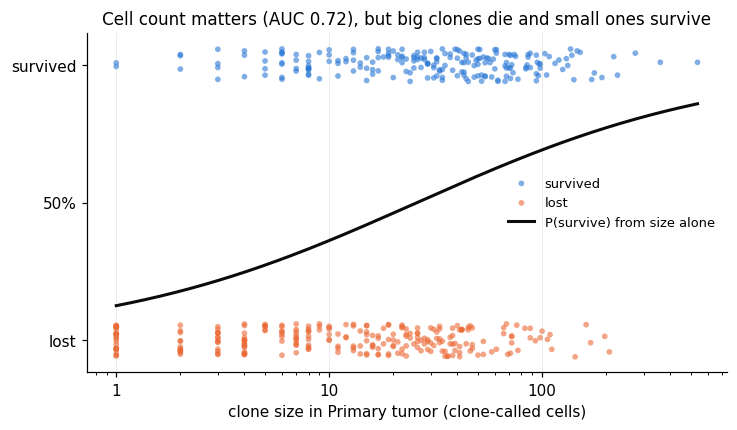

In [6]:
# Each dot is one clone in one Primary tumor; the curve is what size alone predicts.
fig, ax = plt.subplots(figsize=(7.5, 4))
jit = rng.uniform(-0.06, 0.06, len(units))
for surv, color, label in [(True, SURVIVED_COLOR, "survived"), (False, LOST_COLOR, "lost")]:
    d = units.survived == surv
    ax.scatter(units.n_parent[d], y[d] + jit[d], s=14, alpha=0.6, color=color, label=label,
               edgecolor="none")
grid = np.linspace(units.log_n.min(), units.log_n.max(), 200)
p_mean = 1 / (1 + np.exp(-(w_size[0] * grid + w_size[1:].mean())))
ax.plot(np.exp(grid), p_mean, color="#0b0b0b", lw=2, label="P(survive) from size alone")
ax.set_xscale("log")
ax.set_xticks([1, 10, 100]); ax.set_xticklabels(["1", "10", "100"])
ax.set_yticks([0, 0.5, 1]); ax.set_yticklabels(["lost", "50%", "survived"])
ax.set_xlabel("clone size in Primary tumor (clone-called cells)")
ax.set_title(f"Cell count matters (AUC {auc(units.p_size.to_numpy(), y):.2f}), but big clones die "
             "and small ones survive")
ax.legend(loc="center right", fontsize=8.5)
ax.grid(axis="y", visible=False)
plt.show()

In [7]:
# Does a clone that beats its size in one family beat it again in another?
# The three families are independent tumors seeded from the same barcoded pool.
# Rows: clones; columns: families. A clone missing from a family's Primary tumor is NaN and
# drops out of that pair. The null shuffles clones *within* each family, which keeps each
# family's survival rate and size mix exactly as observed.
# GLOSSARY.md: fate is a property of the clone, permutation null
beat = units.pivot(index="clone", columns="family", values="beat_size")
PAIRS = [("A", "B"), ("A", "C"), ("B", "C")]

def cross_family_r(table):
    x, z = [], []
    for a, b in PAIRS:
        d = table[[a, b]].dropna()
        x += list(d[a]); z += list(d[b])
    return np.corrcoef(x, z)[0, 1]

def shuffle_within_family(table):
    out = table.copy()
    for f in FAMILIES:
        ok = out[f].notna()
        out.loc[ok, f] = rng.permutation(out.loc[ok, f].to_numpy())
    return out

r_obs = cross_family_r(beat)
r_null = np.array([cross_family_r(shuffle_within_family(beat)) for _ in range(2000)])
print(f"size-adjusted fate, same clone across families: r = {r_obs:.2f} "
      f"(shuffled clones: {r_null.mean():.2f} ± {r_null.std():.2f}, "
      f"p < {max((r_null >= r_obs).mean(), 1 / len(r_null)):.4f})")

size-adjusted fate, same clone across families: r = 0.38 (shuffled clones: 0.00 ± 0.05, p < 0.0005)


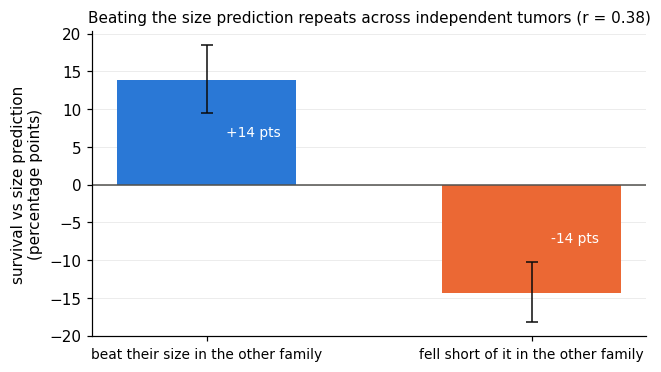

In [8]:
# The same idea as bars: split clones by how they did in one family, then look at
# how they do in another. Height = survival above (+) or below (-) what size predicts.
rows = []
# Both directions of each pair are used (A->B and B->A), so each clone pair contributes twice.
for a, b in PAIRS + [(b, a) for a, b in PAIRS]:
    d = beat[[a, b]].dropna()
    rows += [dict(group="beat their size in the other family", value=v) for v in d[b][d[a] > 0]]
    rows += [dict(group="fell short of it in the other family", value=v) for v in d[b][d[a] <= 0]]
bars = pd.DataFrame(rows)

def boot_ci(v, n=2000):
    v = np.asarray(v)
    m = [rng.choice(v, len(v)).mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, (g, d) in enumerate(bars.groupby("group", sort=False)):
    m, (lo, hi) = 100 * d.value.mean(), 100 * boot_ci(d.value)
    ax.bar(i, m, color=SURVIVED_COLOR if m > 0 else LOST_COLOR, width=0.55, zorder=2)
    ax.errorbar(i, m, yerr=[[m - lo], [hi - m]], color="#0b0b0b", capsize=4, lw=1, zorder=3)
    ax.text(i + 0.06, m / 2, f"{m:+.0f} pts", ha="left", va="center", fontsize=9, color="white")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks([0, 1]); ax.set_xticklabels(bars.group.unique(), fontsize=9)
ax.set_ylabel("survival vs size prediction\n(percentage points)")
ax.set_title(f"Beating the size prediction repeats across independent tumors (r = {r_obs:.2f})",
             fontsize=10)
ax.grid(axis="x", visible=False)
plt.show()

## 2. Survivors already look different in the Primary tumor

If fate is a property of the clone, it should show in the clone's cells
before selection happens. Compare survivors with lost clones, using only
clones with at least 20 cells in the Primary tumor so each clone's profile is
measured reasonably well, and adjusting for size and family throughout.
First the five-state mix, then the full expression profile, then the
question of whether the second adds anything to the first.


In [9]:
MIN_CELLS = 20
big = units[units.n_parent >= MIN_CELLS].reset_index(drop=True)
big["unit"] = big.family + " | " + big.clone
print(f"{len(big)} units with >= {MIN_CELLS} cells: "
      f"{big.survived.sum()} survived, {(~big.survived).sum()} lost")

244 units with >= 20 cells: 142 survived, 102 lost


In [10]:
# Residualise anything on a set of covariates, so comparisons are matched on them.
# Z_size: log(size) + family. Later cells add more covariates.
Z_size = np.column_stack([np.ones(len(big)), big.log_n,
                          pd.get_dummies(big.family, drop_first=True).to_numpy(float)])

# GLOSSARY.md: residualise / adjust for covariates
def residualise(Y, Z):
    Y = np.asarray(Y, float)
    beta, *_ = np.linalg.lstsq(Z, Y, rcond=None)
    return Y - Z @ beta

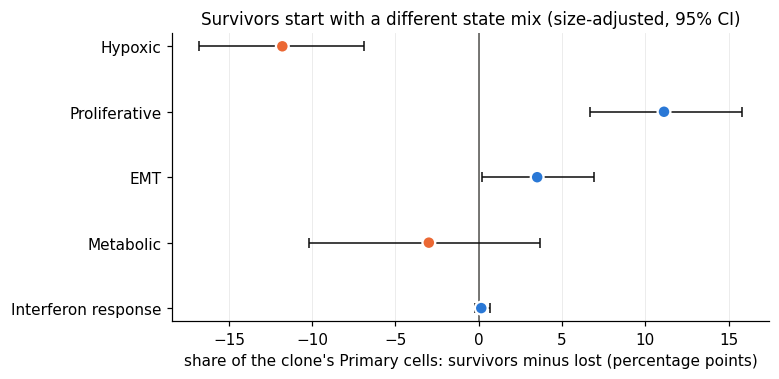

In [11]:
# State mix in the Primary tumor, survivors vs lost (size-adjusted difference).
prim = called[called.stage == "Primary"].assign(unit=lambda d: d.family + " | " + d.clone)
# `mix` is each unit's state fractions over its Primary cells. Residualising the fractions and
# the survival flag on the same Z, then differencing by survival, gives a size- and
# family-adjusted contrast. The bootstrap resamples units.
# GLOSSARY.md: state mix / state fractions, bootstrap over clones
mix = (prim.groupby(["unit", "state"], observed=False).size().unstack(fill_value=0)
           .reindex(big.unit))
mix = mix.div(mix.sum(axis=1), axis=0)
mix_resid = residualise(mix.to_numpy(), Z_size)
s = big.survived.to_numpy()
diff = mix_resid[s].mean(0) - mix_resid[~s].mean(0)

boot = []
for _ in range(2000):
    i = rng.integers(0, len(big), len(big))
    boot.append(mix_resid[i][s[i]].mean(0) - mix_resid[i][~s[i]].mean(0))
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(7, 3.4))
yy = np.arange(len(STATE_NAMES))[::-1]
ax.axvline(0, color=MUTED, lw=1)
ax.errorbar(100 * diff, yy, xerr=[100 * (diff - lo), 100 * (hi - diff)], fmt="none",
            ecolor="#0b0b0b", capsize=3, lw=1)
ax.scatter(100 * diff, yy, s=70, color=[SURVIVED_COLOR if d > 0 else LOST_COLOR for d in diff],
           edgecolor="white", linewidth=1.5, zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(STATE_NAMES)
ax.set_xlabel("share of the clone's Primary cells: survivors minus lost (percentage points)")
ax.set_title("Survivors start with a different state mix (size-adjusted, 95% CI)")
ax.grid(axis="y", visible=False)
plt.show()

In [12]:
# Pseudobulk: each unit's mean log-normalised expression over its Primary cells.
# Streams only those rows from derived/etracer_counts.h5ad (takes about a minute).
# GLOSSARY.md: pseudobulk, gene panel
pb, frac = et.pseudobulk(P, prim.cell_id, prim.unit)
pb = pb.reindex(big.unit)
# `frac` is the share of Primary cells expressing each gene. The 5% filter drops genes that
# are mostly zeros and would only add noise to per-unit means.
genes = frac.index[frac >= 0.05]          # expressed in at least 5% of Primary cells
print(f"{len(big)} units x {len(genes):,} genes")

244 units x 10,419 genes


In [13]:
# Sequencing depth: survivors' cells carry more UMIs, which shifts thousands of genes
# through normalisation. Adjust for it (median log UMI of the clone's Primary cells).
# GLOSSARY.md: UMI, sequencing depth
depth = np.log(prim.groupby("unit").n_umi.median().reindex(big.unit).to_numpy())
print(f"survivors' median UMI is {np.exp(depth[s].mean() - depth[~s].mean()) - 1:+.0%} vs lost clones; "
      f"size-adjusted r(depth, survival) = "
      f"{np.corrcoef(residualise(depth, Z_size), residualise(s.astype(float), Z_size))[0, 1]:.2f}")
Z_depth = np.column_stack([Z_size, depth])
Z_state = np.column_stack([Z_depth, mix.to_numpy()[:, :-1]])   # 4 of the 5 fractions (they sum to 1)

survivors' median UMI is +14% vs lost clones; size-adjusted r(depth, survival) = 0.30


In [14]:
# The test, per gene: correlation between covariate-adjusted expression and
# covariate-adjusted survival. Null: give each clone another clone's survival
# outcomes (all its families at once), redo the adjustment; pooled across genes.
surv_table = big.pivot(index="clone", columns="family", values="survived").astype(float)
ci = surv_table.index.get_indexer(big.clone)
fi = surv_table.columns.get_indexer(big.family)
M = surv_table.to_numpy()

def gene_r(xr, sr):
    xc, sc = xr - xr.mean(0), sr - sr.mean()
    return (xc * sc[:, None]).sum(0) / np.sqrt((xc ** 2).sum(0) * (sc ** 2).sum() + 1e-12)

# GLOSSARY.md: permutation null, pooled null across genes, FDR / Benjamini-Hochberg
def survival_gene_test(Z, n_perm=500, seed=1):
    gen = np.random.default_rng(seed)        # fixed seed: same covariates, same answer
    xr = residualise(pb[genes].to_numpy(), Z)
    r = gene_r(xr, residualise(s.astype(float), Z))
    null = np.empty((n_perm, len(genes)), dtype=np.float32)
    for k in range(n_perm):
        sp = M[gen.permutation(len(M))][ci, fi]                # another clone's outcome, same family
        sp = np.where(np.isnan(sp), s.mean(), sp)
        null[k] = gene_r(xr, residualise(sp, Z))
    # p-values come from the null pooled over all genes and permutations, so the smallest
    # attainable p is 1 / (n_perm * n_genes). q is Benjamini-Hochberg.
    pooled = np.sort(np.abs(null).ravel())
    p = np.maximum(1 - np.searchsorted(pooled, np.abs(r)) / len(pooled), 1 / len(pooled))
    o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    q_out = np.empty_like(q); q_out[o] = np.minimum(q, 1)
    effect = xr[s].mean(0) - xr[~s].mean(0)                    # survivors minus lost
    # `r_cut`: the smallest |r| that clears FDR 10%; drawn as the dashed line in the volcano.
    return dict(r=r, p=p, q=q_out, effect=effect, r_cut=np.abs(r)[q_out < 0.10].min()
                if (q_out < 0.10).any() else np.nan)

In [15]:
# Main test: adjusted for size, family and sequencing depth.
T = survival_gene_test(Z_depth)
effect, r_gene, p_gene, q_gene = T["effect"], T["r"], T["p"], T["q"]
print(f"genes at FDR < 10%: {(q_gene < 0.10).sum():,} of {len(genes):,}")

genes at FDR < 10%: 2,225 of 10,419


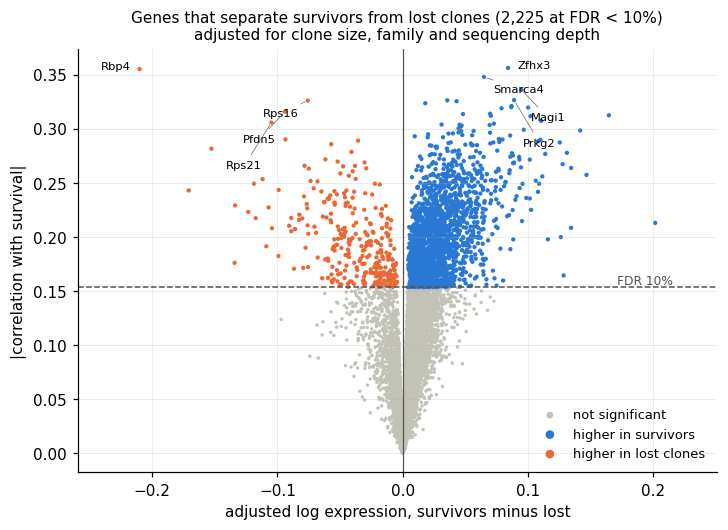

In [16]:
# Volcano: which genes differ between survivors and lost clones, beyond chance.
hit = q_gene < 0.10
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(effect[~hit], np.abs(r_gene[~hit]), s=5, color="#c3c2b7", edgecolor="none",
           rasterized=True, label="not significant")
ax.scatter(effect[hit & (effect > 0)], np.abs(r_gene[hit & (effect > 0)]), s=8,
           color=SURVIVED_COLOR, edgecolor="none", rasterized=True, label="higher in survivors")
ax.scatter(effect[hit & (effect < 0)], np.abs(r_gene[hit & (effect < 0)]), s=8,
           color=LOST_COLOR, edgecolor="none", rasterized=True, label="higher in lost clones")
ax.axhline(T["r_cut"], color=MUTED, lw=1, ls="--")
ax.text(ax.get_xlim()[1], T["r_cut"], "FDR 10%  ", ha="right", va="bottom", fontsize=8, color=MUTED)
# Label the four strongest genes in each direction.
for sign in (1, -1):
    idx = np.where(np.sign(r_gene) == sign)[0]
    for k, i in enumerate(idx[np.argsort(-np.abs(r_gene[idx]))[:4]]):
        ax.annotate(genes[i], (effect[i], abs(r_gene[i])), fontsize=7.5,
                    xytext=(6 * sign, -10 * k), textcoords="offset points",
                    ha="left" if sign > 0 else "right",
                    arrowprops=dict(arrowstyle="-", lw=0.4, color=MUTED))
ax.axvline(0, color=MUTED, lw=0.8)
ax.margins(x=0.12)
ax.set_xlabel("adjusted log expression, survivors minus lost")
ax.set_ylabel("|correlation with survival|")
ax.set_title(f"Genes that separate survivors from lost clones ({hit.sum():,} at FDR < 10%)\n"
             "adjusted for clone size, family and sequencing depth", fontsize=10)
ax.legend(loc="lower right", fontsize=8.5, markerscale=2)
plt.show()

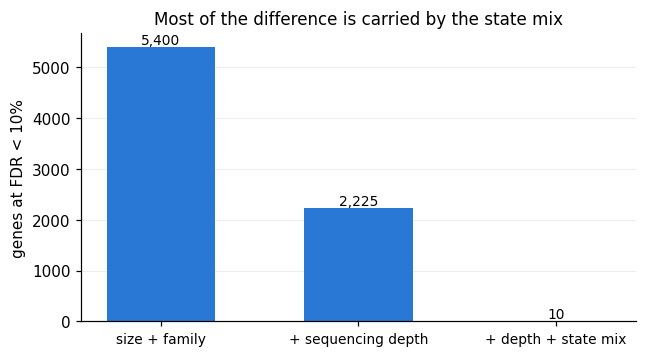

In [17]:
# How much of this is the state mix? Repeat the test with more and more adjustment.
# Same test, three covariate sets. If the state fractions carry the expression differences,
# the hit count should collapse in the third column.
tests = {"size + family": Z_size,
         "+ sequencing depth": Z_depth,
         "+ depth + state mix": Z_state}
n_hits = {k: int((survival_gene_test(Z)["q"] < 0.10).sum()) for k, Z in tests.items()}

fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(n_hits))
ax.bar(x, list(n_hits.values()), color=SURVIVED_COLOR, width=0.55, zorder=2)
for xi, v in zip(x, n_hits.values()):
    ax.text(xi, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(n_hits.keys(), fontsize=9)
ax.set_ylabel("genes at FDR < 10%")
ax.set_title("Most of the difference is carried by the state mix")
ax.grid(axis="x", visible=False)
plt.show()

In [18]:
# The strongest genes in each direction (size, family and depth adjusted).
res = pd.DataFrame({"gene": genes, "effect": effect.round(3), "r": r_gene.round(3),
                    "p": p_gene, "q": q_gene.round(4)}).sort_values("p")
pd.concat([res[res.effect > 0].head(10).assign(direction="higher in survivors"),
           res[res.effect < 0].head(10).assign(direction="higher in lost clones")]).reset_index(drop=True)

,gene,effect,r,p,q,direction
0,Magi1,0.095,0.336,1.919570e-07,0.0004,higher in survivors
1,Zfhx3,0.084,0.356,1.919570e-07,0.0004,higher in survivors
2,Prkg2,0.089,0.326,1.919570e-07,0.0004,higher in survivors
3,Smarca4,0.065,0.348,1.919570e-07,0.0004,higher in survivors
4,Il34,0.036,0.326,3.839140e-07,0.0005,higher in survivors
5,Etv4,0.043,0.325,3.839140e-07,0.0005,higher in survivors
6,Cenpt,0.018,0.323,7.678280e-07,0.0006,higher in survivors
7,4930467D21Rik,0.087,0.320,7.678280e-07,0.0006,higher in survivors
8,Myl12b,0.087,0.321,7.678280e-07,0.0006,higher in survivors
9,Prdx2,0.100,0.319,9.597850e-07,0.0006,higher in survivors


## Summary

- **Clones disappear.** 55% of clones in a Primary tumor are not seen in
  either of its Secondary tumors.
- **Size explains part of it** (AUC 0.72), partly because small survivors
  can be missed.
- **Fate is a property of the clone.** After accounting for size, a clone
  that survives more than expected in one family does so in the other
  families too (r = 0.38; shuffled clones give 0.00 ± 0.05). Clones that beat
  their size in one tumor beat it by about 14 points in another.
- **Survivors already look different in the Primary tumor.** At matched size
  they have about 12 points less Hypoxic and 11 points more Proliferative,
  the direction the eTRACER preprint reports. About 2,200 genes differ at
  FDR < 10% after adjusting for size, family and sequencing depth.
- **Nearly all of that runs through the state mix.** Adjusting for the five
  state fractions too leaves only a handful of genes.

**What this sets up.** Selection acts on clones, it reproduces across
independent mice, and it is only partly visible in expression: survivors
differ from lost clones, but mostly through a five-number state mix, and
size alone already reaches AUC 0.72. So when a flow model pairs Primary
cells with Secondary cells, the barcodes carry something expression does
not: which clones have descendants, and how many. The `coupling_ablation`
notebook asks what a lineage-free coupling, inferred from expression
proximity as standard (unbalanced) OT flow matching does, gets wrong as a
result: clone ancestry, clone growth, and the state transitions the
pairing implies.

Caveats: survivors' cells carry about 14% more UMIs, which may be partly
biological (proliferating cells are larger), so the depth adjustment is
conservative. Clones recur across families, so families are not fully
independent units; the shuffles move whole clones to respect that.
